# Resultados y discusión: presencia en el videoclip interactivo VR

**Fuente de datos:** `Resultados-IPQ.xlsx`, exportación de KoboToolbox ubicada junto a este cuaderno. Se analizan únicamente respuestas con autorización para investigación. Las dos respuestas sin código de participante son válidas según la confirmación del equipo investigador.

**Instrumento y administración:** se utilizaron los 14 enunciados en español del IPQ publicados por Castro et al. (2026), [adaptación española del ITQ e IPQ](https://doi.org/10.1007/s10055-025-01301-2), Apéndice 2. Según el equipo investigador, durante las sesiones presenciales se explicó a los participantes el significado de los anclajes de cada pregunta. El análisis aplica esos anclajes específicos y orienta las respuestas para que valores mayores indiquen mayor presencia.

**Modelo principal:** las tres dimensiones se calculan con el modelo factorial revisado que presenta el artículo. Este modelo retiró de involucramiento el ítem 14 por sus cargas en varios factores. Se muestra además el promedio de involucramiento con los cuatro ítems originales como análisis de sensibilidad. El ítem 8 se informa por separado como presencia general.

El cuaderno evita mostrar códigos, identificadores y comentarios individuales.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

archivo = Path("Resultados-IPQ.xlsx")
if not archivo.exists():
    raise FileNotFoundError(f"No se encontró {archivo.resolve()}")

exportacion = pd.read_excel(archivo)
assert exportacion.shape[1] >= 34, "Cambió la estructura de columnas de la exportación"
assert "research_use_flag" in exportacion, "Falta la columna de consentimiento"

# La exportación contiene caracteres dañados en algunos encabezados; se usan
# las posiciones verificadas del XLSForm y se comprueba el número de ítem.
columnas_ipq = {f"q{i}": exportacion.columns[12 + i] for i in range(1, 15)}
for i, encabezado in enumerate(columnas_ipq.values(), start=1):
    assert str(encabezado).startswith(f"{i}."), f"Cambió el orden del ítem {i}"

consentidas = exportacion.loc[
    pd.to_numeric(exportacion["research_use_flag"], errors="coerce").eq(1)
].copy()
respuestas = pd.DataFrame({
    nombre: pd.to_numeric(consentidas[columna], errors="coerce")
    for nombre, columna in columnas_ipq.items()
}, index=consentidas.index)

# No se imputan respuestas faltantes ni se excluyen registros por falta de código.
valores_fuera_de_rango = ((respuestas < -3) | (respuestas > 3)).sum().sum()
assert valores_fuera_de_rango == 0, "Se encontraron respuestas IPQ fuera de -3 a +3"


## 1. Revisión de la base

La **Tabla 1** resume el número de registros y la completitud del IPQ. Para cada indicador posterior se usan solamente las respuestas disponibles para sus ítems; por eso cambia el denominador. *Fuente: elaboración propia a partir de la exportación de KoboToolbox.*

In [2]:
faltantes_por_fila = respuestas.isna().sum(axis=1)
revision = pd.DataFrame({
    "Medida": [
        "Registros exportados", "Registros con consentimiento",
        "IPQ completo (14 ítems)", "IPQ con 1 respuesta faltante",
        "IPQ con 2 respuestas faltantes"#, "Registros consentidos sin código"
    ],
    "Cantidad": [
        len(exportacion), len(consentidas), int((faltantes_por_fila == 0).sum()),
        int((faltantes_por_fila == 1).sum()),
        int((faltantes_por_fila == 2).sum())#,
        #int(consentidas.iloc[:, 10].isna().sum())
    ]
})
display(revision)


,Medida,Cantidad
0,Registros exportados,35
1,Registros con consentimiento,35
2,IPQ completo (14 ítems),31
3,IPQ con 1 respuesta faltante,1
4,IPQ con 2 respuestas faltantes,3


## 2. Puntuaciones del IPQ

Las respuestas se orientan a una escala de $-3$ a $+3$, donde un valor mayor indica más presencia. Conforme a los anclajes de la [adaptación española, Apéndice 2](https://doi.org/10.1007/s10055-025-01301-2), se invierte el signo de los ítems **2 y 4** (anclajes de realismo y consistencia), **11** (atención al entorno real) y **13** (sensación de mirar fotografías). El ítem **6** conserva su signo porque sus extremos van de «no me sentí presente» a «me sentí presente». También se conserva el signo del ítem **1**, cuyos extremos van de mayor a menor conciencia del mundo real.

Las puntuaciones de cada dimensión son el promedio de sus ítems orientados. Se exige respuesta en todos los ítems de cada puntuación y no se imputan datos faltantes. La **Tabla 2** muestra el modelo principal y una fila de sensibilidad para involucramiento con el ítem 14. *Fuente: elaboración propia a partir de `Resultados-IPQ.xlsx` y la asignación de ítems de Castro et al. (2026).*

In [3]:
items_orientados = respuestas.copy()
for nombre in ("q2", "q4", "q11", "q13"):
    items_orientados[nombre] = -items_orientados[nombre]

def promedio_completo(columnas):
    valores = items_orientados[columnas]
    return valores.mean(axis=1).where(valores.notna().all(axis=1))

puntuaciones = pd.DataFrame(index=respuestas.index)
puntuaciones["Presencia general (ítem 8)"] = items_orientados["q8"]
puntuaciones["Presencia espacial (5 ítems)"] = promedio_completo(["q3", "q6", "q9", "q10", "q13"])
puntuaciones["Involucramiento (3 ítems, modelo revisado)"] = promedio_completo(["q1", "q7", "q11"])
puntuaciones["Realismo (4 ítems)"] = promedio_completo(["q2", "q4", "q5", "q12"])
puntuaciones["Involucramiento (4 ítems, sensibilidad)"] = promedio_completo(["q1", "q7", "q11", "q14"])

tabla_puntuaciones = pd.DataFrame({
    "Indicador": puntuaciones.columns,
    "n": puntuaciones.count().to_numpy(),
    "Media": puntuaciones.mean().to_numpy(),
    "DE": puntuaciones.std(ddof=1).to_numpy(),
    "Mediana": puntuaciones.median().to_numpy(),
    "Respuestas positivas": puntuaciones.gt(0).sum().to_numpy()
})
display(tabla_puntuaciones.round(2))


,Indicador,n,Media,DE,Mediana,Respuestas positivas
0,Presencia general (ítem 8),34,2.03,1.19,2.00,32
1,Presencia espacial (5 ítems),32,1.33,0.79,1.40,31
2,"Involucramiento (3 ítems, modelo revisado)",34,0.36,0.90,0.33,20
3,Realismo (4 ítems),34,-0.45,0.55,-0.50,5
4,"Involucramiento (4 ítems, sensibilidad)",34,0.71,0.75,0.75,26


La **Figura 1** presenta el perfil medio del ítem general y las tres dimensiones del modelo principal. Las barras muestran promedios descriptivos, sin inferencia poblacional. *Fuente: elaboración propia a partir de `Resultados-IPQ.xlsx`.*

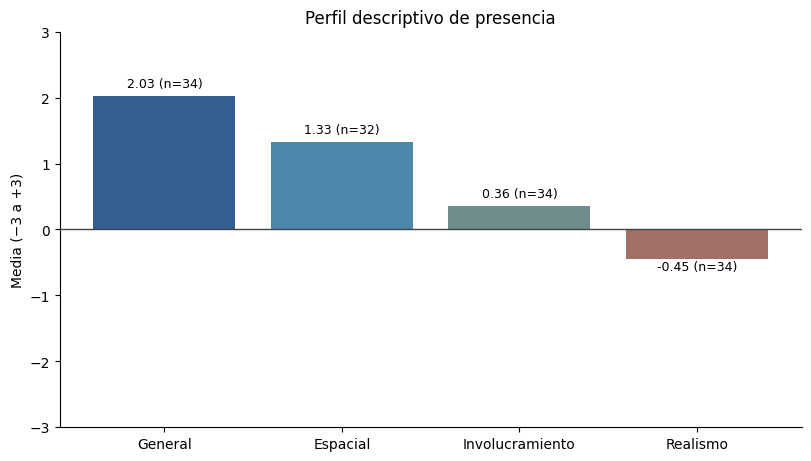

In [4]:
perfil = puntuaciones.iloc[:, :4]
medias = perfil.mean()
etiquetas = ["General", "Espacial", "Involucramiento", "Realismo"]
colores = ["#355f91", "#4d87a9", "#708b8b", "#a27067"]
fig, eje = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
barras = eje.bar(etiquetas, medias.values, color=colores)
eje.axhline(0, color="#444444", linewidth=1)
eje.set(title="Perfil descriptivo de presencia", ylabel="Media (−3 a +3)", ylim=(-3, 3))
eje.spines[["top", "right"]].set_visible(False)
for barra, media, n in zip(barras, medias, perfil.count()):
    desplazamiento = 0.08 if media >= 0 else -0.22
    eje.text(barra.get_x() + barra.get_width()/2, media + desplazamiento,
             f"{media:.2f} (n={n})", ha="center", va="bottom", fontsize=9)
plt.show()


## 3. Resultados redactados para el capítulo

El siguiente bloque genera un texto con las cifras de esta exportación. Cita la Tabla 1, la Tabla 2 y la Figura 1 al trasladarlas a la tesis.

In [5]:
def es(numero, decimales=2):
    return f"{numero:.{decimales}f}".replace(".", ",")

n_general = int(puntuaciones.iloc[:, 0].count())
positivos_general = int(puntuaciones.iloc[:, 0].gt(0).sum())
n_espacial = int(puntuaciones.iloc[:, 1].count())
positivos_espacial = int(puntuaciones.iloc[:, 1].gt(0).sum())
n_involucramiento = int(puntuaciones.iloc[:, 2].count())
positivos_involucramiento = int(puntuaciones.iloc[:, 2].gt(0).sum())
neutros_involucramiento = int(puntuaciones.iloc[:, 2].eq(0).sum())
negativos_involucramiento = int(puntuaciones.iloc[:, 2].lt(0).sum())
n_realismo = int(puntuaciones.iloc[:, 3].count())
negativos_realismo = int(puntuaciones.iloc[:, 3].lt(0).sum())

texto_resultados = f"""
### Texto propuesto: Resultados

La base contenía **{len(exportacion)} registros** con autorización para el uso de sus respuestas. **{int((faltantes_por_fila == 0).sum())}** respondieron los 14 ítems del IPQ; los otros **{int((faltantes_por_fila > 0).sum())}** presentaron una o dos respuestas faltantes (Tabla 1). Se conservaron dos respuestas válidas sin código de participante.

La presencia general obtuvo una media de **{es(puntuaciones.iloc[:, 0].mean())}** (DE = {es(puntuaciones.iloc[:, 0].std(ddof=1))}; n = {n_general}). **{positivos_general} de {n_general}** respuestas fueron positivas. La presencia espacial presentó una media de **{es(puntuaciones.iloc[:, 1].mean())}** (DE = {es(puntuaciones.iloc[:, 1].std(ddof=1))}; n = {n_espacial}), con **{positivos_espacial} de {n_espacial}** puntuaciones positivas (Tabla 2 y Figura 1).

En el modelo revisado, involucramiento obtuvo una media de **{es(puntuaciones.iloc[:, 2].mean())}** (DE = {es(puntuaciones.iloc[:, 2].std(ddof=1))}; n = {n_involucramiento}). De las {n_involucramiento} puntuaciones, **{positivos_involucramiento} fueron positivas, {neutros_involucramiento} iguales a cero y {negativos_involucramiento} negativas**. El realismo presentó una media de **{es(puntuaciones.iloc[:, 3].mean())}** (DE = {es(puntuaciones.iloc[:, 3].std(ddof=1))}; n = {n_realismo}); **{negativos_realismo} de {n_realismo}** puntuaciones de esta dimensión fueron negativas (Tabla 2 y Figura 1).

Al incluir el ítem 14 en el promedio original de involucramiento, la media fue de **{es(puntuaciones.iloc[:, 4].mean())}** (DE = {es(puntuaciones.iloc[:, 4].std(ddof=1))}; n = {int(puntuaciones.iloc[:, 4].count())}). La diferencia respecto al modelo revisado muestra la influencia de ese ítem en la descripción de la muestra (Tabla 2).
"""
display(Markdown(texto_resultados))



### Texto propuesto: Resultados

La base contenía **35 registros** con autorización para el uso de sus respuestas. **31** respondieron los 14 ítems del IPQ; los otros **4** presentaron una o dos respuestas faltantes (Tabla 1). Se conservaron dos respuestas válidas sin código de participante.

La presencia general obtuvo una media de **2,03** (DE = 1,19; n = 34). **32 de 34** respuestas fueron positivas. La presencia espacial presentó una media de **1,33** (DE = 0,79; n = 32), con **31 de 32** puntuaciones positivas (Tabla 2 y Figura 1).

En el modelo revisado, involucramiento obtuvo una media de **0,36** (DE = 0,90; n = 34). De las 34 puntuaciones, **20 fueron positivas, 3 iguales a cero y 11 negativas**. El realismo presentó una media de **-0,45** (DE = 0,55; n = 34); **26 de 34** puntuaciones de esta dimensión fueron negativas (Tabla 2 y Figura 1).

Al incluir el ítem 14 en el promedio original de involucramiento, la media fue de **0,71** (DE = 0,75; n = 34). La diferencia respecto al modelo revisado muestra la influencia de ese ítem en la descripción de la muestra (Tabla 2).


## 4. Discusión e interpretación

**Objetivos de implementación.** El código del proyecto define canales de eventos, una secuencia configurable y un reloj musical compartido. Este cuaderno analiza respuestas de usuarios; no contiene registros instrumentados de latencia, tiempo de carga o desfase audiovisual. Las puntuaciones de presencia no demuestran por sí mismas un efecto causal de la arquitectura.

**Presencia espacial y general.** Las puntuaciones fueron mayoritariamente positivas en ambas medidas. Esto indica que, dentro de la muestra evaluada, la experiencia produjo una sensación subjetiva de estar en el entorno virtual. Sin un grupo de comparación, no puede atribuirse esa percepción exclusivamente a la secuenciación, al contenido artístico, al visor o a alguna mecánica concreta.

**Involucramiento.** Esta dimensión refleja la atención dedicada al entorno virtual y la disminución de la atención al entorno real. La media de 0,36 quedó ligeramente por encima del punto central de la escala (0) y fue menor que la media de presencia espacial. Hubo 20 puntuaciones positivas, tres iguales a cero y 11 negativas entre 34 respuestas completas. Esto sugiere involucramiento para una parte de la muestra, con diferencias apreciables entre participantes; el promedio no representa una concentración uniforme en el mundo virtual. No se asigna una categoría de «bajo», «medio» o «alto», porque el estudio no definió umbrales para esta muestra.

**Realismo.** El realismo presentó una media negativa y 26 de 34 puntuaciones por debajo de cero. Este resultado describe una percepción de realismo distinta de la sensación de presencia: los participantes podían sentirse dentro de la experiencia sin considerar que su mundo visual fuera equivalente al mundo real. Esa explicación es una interpretación posible, no una causa demostrada. El [artículo de Castro et al.](https://doi.org/10.1007/s10055-025-01301-2) también señala dificultades de consistencia interna en la dimensión de realismo, por lo que conviene interpretar esa media con cautela.

**Modelo revisado y sensibilidad.** El modelo factorial revisado del artículo excluye el ítem 14 de involucramiento por sus cargas en varios factores. En esta muestra, incluirlo eleva la media de 0,36 a 0,71. Se informa esta comparación para mostrar la sensibilidad de la puntuación a la definición de la subescala; la interpretación principal sigue el modelo revisado.

**Límites del diseño.** La muestra se obtuvo por conveniencia y no hubo grupo de comparación. Treinta y cuatro participantes indicaron que no era su primera vez en VR y uno no respondió esa pregunta. Los resultados describen a quienes respondieron la encuesta; no permiten generalizar estadísticamente a todos los usuarios ni aceptar o rechazar una hipótesis causal no formulada. Una evaluación posterior podría añadir mediciones de sincronización y una condición de comparación para estudiar la relación entre el sistema técnico y la presencia percibida.